# 02 · Cálculo de probabilidades

Una pequeña biblioteca para calcular probabilidades: eventos dados por conjuntos o por predicados, urnas y combinaciones, distribuciones no uniformes y el problema de Newton–Pepys.

**Contenido**

1. Probabilidad de un evento
2. Urnas: extracción sin reemplazo
3. Eventos definidos por predicados
4. Distribuciones de probabilidad generales
5. El problema de Newton–Pepys

In [1]:
from fractions import Fraction
from itertools import combinations
from math import comb

import matplotlib.pyplot as plt
from scipy.stats import binom

## 1. Probabilidad de un evento

En un espacio de probabilidad clásico $(\Omega,\mathcal{E},\mathbb{P})$ todos los resultados son equiprobables y

$$\mathbb{P}:\mathcal{E}\to[0,1],\qquad E\mapsto\frac{\#E}{\#\Omega}.$$

El módulo `fractions` permite trabajar con números racionales exactos.

In [2]:
def P(evento, espacio):
    """Probabilidad clásica de un evento (conjunto) en un espacio finito."""
    return Fraction(len(evento & espacio), len(espacio))

D = {1, 2, 3, 4, 5, 6}
par = {2, 4, 6}
P(par, D)

Fraction(1, 2)

## 2. Urnas: extracción sin reemplazo

Una urna contiene $23$ bolas: $8$ blancas (W), $6$ azules (B) y $9$ rojas (R):

> ⚪⚪⚪⚪⚪⚪⚪⚪ 🔵🔵🔵🔵🔵🔵 🔴🔴🔴🔴🔴🔴🔴🔴🔴

Se extraen $6$ bolas al azar, sin reemplazo. (El cuaderno 03 estudia las urnas a fondo, con y sin reemplazo.) Calculemos la probabilidad de que

1. todas sean rojas;
2. $3$ sean azules, $2$ blancas y $1$ roja;
3. exactamente $4$ sean blancas.

Primero etiquetamos cada bola para que sean distinguibles.

In [3]:
def etiquetas(color, n):
    return {f"{color}{k}" for k in range(1, n + 1)}

urna = etiquetas("W", 8) | etiquetas("B", 6) | etiquetas("R", 9)
len(urna)

23

El espacio muestral es el conjunto de subconjuntos de $6$ bolas. `itertools.combinations(iterable, r)` produce las subsucesiones de longitud $r$ sin repetición; los elementos se distinguen por su posición, no por su valor. Representamos cada combinación como una cadena para poder contar colores con `.count`.

In [4]:
def combinaciones(items, r):
    return {" ".join(c) for c in combinations(sorted(items), r)}

U6 = combinaciones(urna, 6)
len(U6) == comb(23, 6)

True

In [5]:
r6 = {s for s in U6 if s.count("R") == 6}
b3w2r1 = {s for s in U6 if s.count("B") == 3 and s.count("W") == 2 and s.count("R") == 1}
w4 = {s for s in U6 if s.count("W") == 4}

BOLA = {"W": "⚪", "B": "🔵", "R": "🔴"}
ejemplo = sorted(b3w2r1)[0]
print("un resultado de 3 azules, 2 blancas y 1 roja:", " ".join(BOLA[b[0]] for b in ejemplo.split()))
P(r6, U6), P(b3w2r1, U6), P(w4, U6)

un resultado de 3 azules, 2 blancas y 1 roja: 🔵 🔵 🔵 🔴 ⚪ ⚪


(Fraction(4, 4807), Fraction(240, 4807), Fraction(350, 4807))

### Comprobación con la distribución hipergeométrica

Contar subconjuntos uno por uno es útil para verificar, pero la respuesta exacta sale de las fórmulas combinatorias:

$$\mathbb{P}(\text{6 rojas})=\frac{\binom96}{\binom{23}6},\qquad \mathbb{P}(3B,2W,1R)=\frac{\binom63\binom82\binom91}{\binom{23}6},\qquad \mathbb{P}(\text{4 blancas})=\frac{\binom84\binom{15}2}{\binom{23}6}.$$

In [6]:
total = comb(23, 6)
formulas = (Fraction(comb(9, 6), total),
            Fraction(comb(6, 3) * comb(8, 2) * comb(9, 1), total),
            Fraction(comb(8, 4) * comb(15, 2), total))
formulas == (P(r6, U6), P(b3w2r1, U6), P(w4, U6))

True

## 3. Eventos definidos por predicados

Muchas veces un evento se describe por una propiedad: «el resultado es par» es el conjunto

$$\{n\in\{1,\dots,6\}:\ n\equiv 0 \pmod 2\}=\{2,4,6\}.$$

Extendemos `P` para que acepte también un **predicado**, es decir, una función que devuelve `True` exactamente en los resultados del evento.

In [7]:
def tal_que(predicado, coleccion):
    return {e for e in coleccion if predicado(e)}

def P(evento, espacio):
    if callable(evento):
        evento = tal_que(evento, espacio)
    return Fraction(len(evento & espacio), len(espacio))

def es_par(n):
    return n % 2 == 0

tal_que(es_par, D), P(es_par, D), P(lambda n: n >= 5, D)

({2, 4, 6}, Fraction(1, 2), Fraction(1, 3))

## 4. Distribuciones de probabilidad generales

Si $X:\Omega\to R_X$ es una variable aleatoria discreta, su ley asigna a cada valor un peso $\mathbb{P}(X=k)\ge 0$ con

$$\sum_{k\in R_X}\mathbb{P}(X=k)=1.$$

La clase `DistProb` es un diccionario que normaliza sus pesos. Con ella `P` deja de ser un conteo y pasa a ser una suma de pesos.

In [8]:
class DistProb(dict):
    """Diccionario resultado -> probabilidad, normalizado a suma 1."""

    def __init__(self, mapping=(), **kwargs):
        super().__init__(mapping, **kwargs)
        total = sum(self.values())
        for resultado, peso in self.items():
            if peso < 0:
                raise ValueError("los pesos deben ser no negativos")
            self[resultado] = peso / total


def P(evento, espacio):
    if callable(evento):
        evento = tal_que(evento, espacio)
    if isinstance(espacio, DistProb):
        return sum(espacio[o] for o in espacio if o in evento)
    return Fraction(len(evento & espacio), len(espacio))


def conjunta(A, B, sep=""):
    """Ley conjunta de dos experimentos independientes."""
    return DistProb({a + sep + b: A[a] * B[b] for a in A for b in B})

Para un dado basta distinguir si sale `6` o no (`-`). La ley de $n$ dados independientes se obtiene aplicando `conjunta` repetidamente.

In [9]:
dado = DistProb({"6": Fraction(1, 6), "-": Fraction(5, 6)})

def dados(n):
    return dado if n == 1 else conjunta(dado, dados(n - 1))

dados(3)

{'666': Fraction(1, 216),
 '66-': Fraction(5, 216),
 '6-6': Fraction(5, 216),
 '6--': Fraction(25, 216),
 '-66': Fraction(5, 216),
 '-6-': Fraction(25, 216),
 '--6': Fraction(25, 216),
 '---': Fraction(125, 216)}

## 5. El problema de Newton–Pepys

En 1693 Samuel Pepys preguntó a Isaac Newton cuál de estos eventos es más probable:

1. al lanzar $6$ dados se obtiene al menos un $6$;
2. al lanzar $12$ dados se obtienen al menos dos $6$;
3. al lanzar $18$ dados se obtienen al menos tres $6$.

In [10]:
def al_menos(k, resultado):
    return lambda s: s.count(resultado) >= k

respuestas = {6 * k: P(al_menos(k, "6"), dados(6 * k)) for k in (1, 2, 3)}
{n: float(p) for n, p in respuestas.items()}

{6: 0.6651020233196159, 12: 0.6186673737323087, 18: 0.5973456859477232}

Newton respondió correctamente: el primer evento es el más probable. El número de seises en $6k$ dados es $\mathrm{Bin}(6k,1/6)$, así que

$$\mathbb{P}(\text{al menos } k \text{ seises})=1-\sum_{j=0}^{k-1}\binom{6k}{j}\Big(\frac16\Big)^j\Big(\frac56\Big)^{6k-j}.$$

La sucesión decrece en $k$ y tiende a $1/2$, como predice el teorema central del límite (la media de $\mathrm{Bin}(6k,1/6)$ es exactamente $k$).

[np.float64(0.665102), np.float64(0.618667), np.float64(0.597346)] exacto: [0.665102, 0.618667, 0.597346]


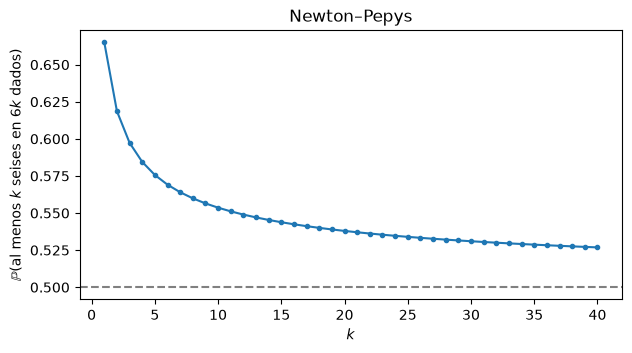

In [11]:
ks = range(1, 41)
probs = [binom.sf(k - 1, 6 * k, 1 / 6) for k in ks]
print([round(p, 6) for p in probs[:3]], "exacto:", [round(float(p), 6) for p in respuestas.values()])

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(ks, probs, "o-", ms=3)
ax.axhline(0.5, color="gray", ls="--")
ax.set_xlabel("$k$")
ax.set_ylabel(r"$\mathbb{P}(\text{al menos } k \text{ seises en } 6k \text{ dados})$")
ax.set_title("Newton–Pepys")
plt.show()

## Ejercicios

1. Con la urna anterior, calcula la probabilidad de que las $6$ bolas no sean todas del mismo color.
2. Usa `DistProb` para modelar un dado cargado con $\mathbb{P}(6)=1/4$ y repite el problema de Newton–Pepys.
3. Demuestra que $\mathbb{P}(\text{al menos un 6 en 6 dados})=1-(5/6)^6$.